In [1]:
import glob, os
import h5py
import numpy as np
import pandas as pd

mat_files = sorted(glob.glob("/kaggle/input/**/*.mat", recursive=True))

rows = []
for path in mat_files:
    with h5py.File(path, "r") as f:
        d = f["cjdata"]
        label = int(np.array(d["label"]).item())
        pid = "".join(chr(c) for c in np.array(d["PID"]).flatten())
    rows.append({
        "path": path,
        "slice_id": os.path.splitext(os.path.basename(path))[0],
        "label": label,
        "pid": pid,
    })

df = pd.DataFrame(rows)
df["class_name"] = df["label"].map({1: "meningioma", 2: "glioma", 3: "pituitary"})
df.head()

,path,slice_id,label,pid,class_name
0,/kaggle/input/datasets/hieuvodoanminh/jun-chen...,1,1,100360,meningioma
1,/kaggle/input/datasets/hieuvodoanminh/jun-chen...,10,1,101016,meningioma
2,/kaggle/input/datasets/hieuvodoanminh/jun-chen...,100,1,107494,meningioma
3,/kaggle/input/datasets/hieuvodoanminh/jun-chen...,101,1,107494,meningioma
4,/kaggle/input/datasets/hieuvodoanminh/jun-chen...,102,1,107494,meningioma


In [2]:
print("slices:", len(df))
print("patients:", df["pid"].nunique())
print(df["class_name"].value_counts())
print("max tumor types per patient:", df.groupby("pid")["label"].nunique().max())
print(df.groupby("pid").size().describe())

slices: 3064
patients: 233
class_name
glioma        1426
pituitary      930
meningioma     708
Name: count, dtype: int64
max tumor types per patient: 1
count    233.000000
mean      13.150215
std        7.655779
min        1.000000
25%        7.000000
50%       13.000000
75%       18.000000
max       38.000000
dtype: float64


In [5]:
rng = np.random.default_rng(42)

patients = df.groupby("pid")["label"].first().reset_index()   # one row per patient

split_of = {}
for label, group in patients.groupby("label"):
    pids = group["pid"].to_numpy().copy()
    rng.shuffle(pids)
    n = len(pids)
    n_train = round(0.80 * n)
    n_val = round(0.10 * n)
    for p in pids[:n_train]:
        split_of[p] = "train"
    for p in pids[n_train:n_train + n_val]:
        split_of[p] = "val"
    for p in pids[n_train + n_val:]:
        split_of[p] = "test"

df["split"] = df["pid"].map(split_of)

In [6]:
train_p = set(df[df.split == "train"].pid)
val_p   = set(df[df.split == "val"].pid)
test_p  = set(df[df.split == "test"].pid)

assert len(train_p & val_p) == 0
assert len(train_p & test_p) == 0
assert len(val_p & test_p) == 0
print("No patient appears in more than one split.")

print(pd.crosstab(df["split"], df["class_name"], margins=True))
print(df.groupby("split")["pid"].nunique())

No patient appears in more than one split.
class_name  glioma  meningioma  pituitary   All
split                                          
test           108          43         99   250
train         1141         585        723  2449
val            177          80        108   365
All           1426         708        930  3064
split
test      23
train    187
val       23
Name: pid, dtype: int64


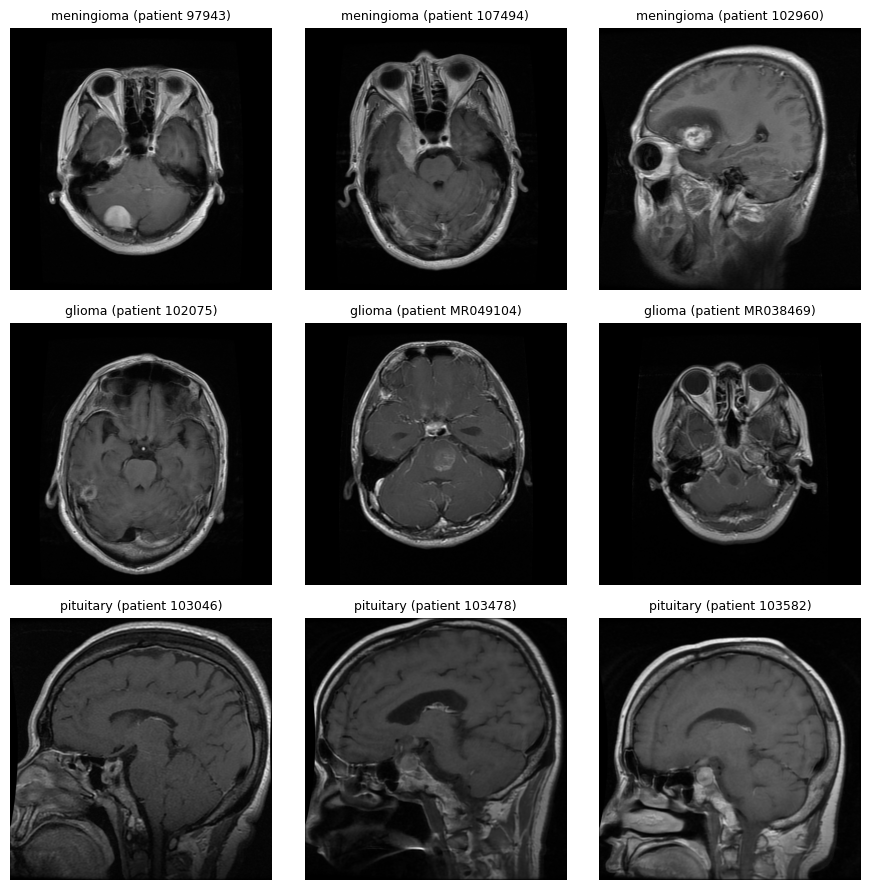

In [7]:
import matplotlib.pyplot as plt

def load_slice(path):
    with h5py.File(path, "r") as f:
        img = np.array(f["cjdata"]["image"]).T.astype(np.float32)
    return (img - img.min()) / (img.max() - img.min() + 1e-8)

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row, (label, name) in enumerate({1: "meningioma", 2: "glioma", 3: "pituitary"}.items()):
    sample = df[df.label == label].drop_duplicates("pid").sample(3, random_state=0)
    for col, (_, r) in enumerate(sample.iterrows()):
        axes[row, col].imshow(load_slice(r["path"]), cmap="gray")
        axes[row, col].set_title(f"{name} (patient {r['pid']})", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [9]:
df.drop(columns=["path"]).to_csv("/kaggle/working/slice_info.csv", index=False)